# Chapter 14: Learning to Predict Multiple Outputs

## Learning Objectives

This chapter extends regression to models that predict more than one target value.

The objectives are:
1. Understand multi-output regression.
2. Build a neural network with multiple output neurons.
3. Train the network using a multi-dimensional target.
4. Evaluate predictions for each output.

## 1. Predicting Multiple Outputs

A neural network can predict multiple numerical values from the same input.

For example, a model could predict two related measurements from one feature.

In multi-output regression, the target contains multiple columns. The output layer must have the same number of neurons as the number of target variables.

The loss function compares all predicted outputs with their corresponding target values.

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# One input feature
X = torch.linspace(-2, 2, 200).reshape(-1, 1)

# Two target outputs
y1 = 2 * X + 1
y2 = -3 * X + 0.5

# Combine both targets into one matrix
Y = torch.cat((y1, y2), dim=1)

print("Input shape:", X.shape)
print("Target shape:", Y.shape)

print("\nFirst five inputs:")
print(X[:5])

print("\nFirst five target rows:")
print(Y[:5])

Input shape: torch.Size([200, 1])
Target shape: torch.Size([200, 2])

First five inputs:
tensor([[-2.0000],
        [-1.9799],
        [-1.9598],
        [-1.9397],
        [-1.9196]])

First five target rows:
tensor([[-3.0000,  6.5000],
        [-2.9598,  6.4397],
        [-2.9196,  6.3794],
        [-2.8794,  6.3191],
        [-2.8392,  6.2588]])


In [2]:
# One input feature and two output values
model = nn.Linear(
    in_features=1,
    out_features=2
)

print(model)
print("\nInitial weights:")
print(model.weight.data)

print("\nInitial biases:")
print(model.bias.data)

Linear(in_features=1, out_features=2, bias=True)

Initial weights:
tensor([[0.7645],
        [0.8300]])

Initial biases:
tensor([-0.2343,  0.9186])


In [3]:
loss_function = nn.MSELoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
)

epochs = 1000
loss_history = []

In [4]:
for epoch in range(epochs):
    # Forward pass
    predictions = model(X)

    # Calculate loss across both outputs
    loss = loss_function(predictions, Y)

    # Reset gradients
    optimizer.zero_grad()

    # Backpropagation
    loss.backward()

    # Update model parameters
    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 200 == 0:
        print(
            f"Epoch {epoch + 1}/{epochs}, "
            f"Loss: {loss.item():.6f}"
        )

Epoch 200/1000, Loss: 0.064987
Epoch 400/1000, Loss: 0.000497
Epoch 600/1000, Loss: 0.000006
Epoch 800/1000, Loss: 0.000000
Epoch 1000/1000, Loss: 0.000000


In [5]:
model.eval()

with torch.no_grad():
    predictions = model(X)

mse_per_output = torch.mean(
    (predictions - Y) ** 2,
    dim=0
)

print("Final overall MSE:", loss_function(predictions, Y).item())
print("MSE for output 1:", mse_per_output[0].item())
print("MSE for output 2:", mse_per_output[1].item())

print("\nFirst five predictions:")
print(predictions[:5])

print("\nFirst five actual targets:")
print(Y[:5])

Final overall MSE: 1.656731529742217e-09
MSE for output 1: 2.877985183502574e-09
MSE for output 2: 4.354781535376162e-10

First five predictions:
tensor([[-3.0000,  6.5000],
        [-2.9598,  6.4397],
        [-2.9196,  6.3794],
        [-2.8794,  6.3191],
        [-2.8392,  6.2588]])

First five actual targets:
tensor([[-3.0000,  6.5000],
        [-2.9598,  6.4397],
        [-2.9196,  6.3794],
        [-2.8794,  6.3191],
        [-2.8392,  6.2588]])


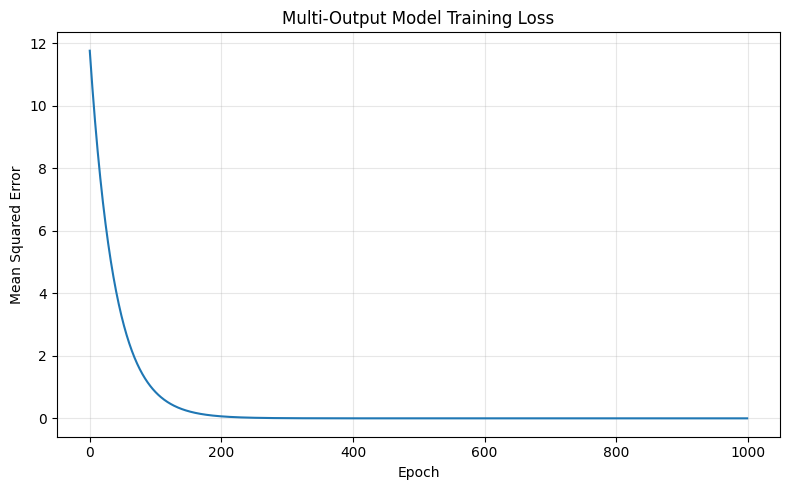

In [6]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.title("Multi-Output Model Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

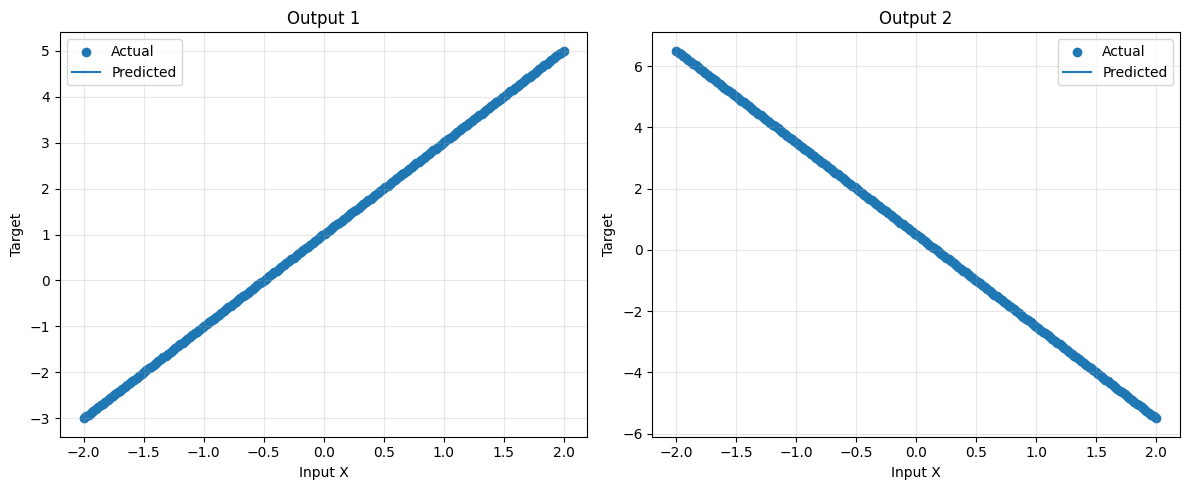

In [7]:
X_plot = X.numpy().flatten()
Y_actual = Y.numpy()
Y_predicted = predictions.numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(X_plot, Y_actual[:, 0], label="Actual")
axes[0].plot(X_plot, Y_predicted[:, 0], label="Predicted")
axes[0].set_title("Output 1")
axes[0].set_xlabel("Input X")
axes[0].set_ylabel("Target")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].scatter(X_plot, Y_actual[:, 1], label="Actual")
axes[1].plot(X_plot, Y_predicted[:, 1], label="Predicted")
axes[1].set_title("Output 2")
axes[1].set_xlabel("Input X")
axes[1].set_ylabel("Target")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Conclusion

Multi-output regression allows a single neural network to predict several numerical targets simultaneously.

The number of output neurons must match the number of target variables. During training, the loss function evaluates the difference between predictions and targets, and backpropagation updates the model parameters.

In this experiment, one input feature is used to predict two different numerical outputs. The dataset is synthetic and is intended to demonstrate the training process.